# Mini Project 2: Operations & Logistics Analytics

**Objective:** Analyze logistics operations, delivery delays, carrier reliability, and warehouse fulfillment efficiency using Python and SQLite.

In [1]:
import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Load data from SQLite
db_paths = ["../Data/Databases/operations.db", "../../Data/Databases/operations.db", "Data/Databases/operations.db"]
db_path = next((p for p in db_paths if os.path.exists(p)), "Data/Databases/operations.db")
conn = sqlite3.connect(db_path)
df = pd.read_sql("SELECT * FROM shipments", conn)
conn.close()

print(f"Loaded {len(df)} records from {db_path}")
df.head()

Loaded 1000 records from ../../Data/Databases/operations.db


,shipment_id,warehouse,carrier,shipping_cost,estimated_days,actual_days,status,delay_days
0,1,Chicago,UPS,13.33,5,6,Delayed,1
1,2,Houston,USPS,29.39,4,9,Delayed,5
2,3,New York,FedEx,44.28,5,4,On Time,0
3,4,Chicago,FedEx,37.95,3,3,On Time,0
4,5,Chicago,FedEx,41.30,3,8,Delayed,5


## 1. Exploratory Data Analysis & Schema Inspection

In [2]:
print("--- Dataset Summary ---")
print(df.info())
print("\n--- Descriptive Statistics ---")
display(df.describe()) if "display" in globals() else print(df.describe())
print("\n--- Null Value Check ---")
print(df.isnull().sum())

--- Dataset Summary ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   shipment_id     1000 non-null   int64  
 1   warehouse       1000 non-null   str    
 2   carrier         1000 non-null   str    
 3   shipping_cost   1000 non-null   float64
 4   estimated_days  1000 non-null   int64  
 5   actual_days     1000 non-null   int64  
 6   status          1000 non-null   str    
 7   delay_days      1000 non-null   int64  
dtypes: float64(1), int64(4), str(3)
memory usage: 81.2 KB
None

--- Descriptive Statistics ---
       shipment_id  shipping_cost  estimated_days  actual_days   delay_days
count  1000.000000    1000.000000     1000.000000  1000.000000  1000.000000
mean    500.500000      27.815770        4.020000     5.005000     1.785000
std     288.819436      13.148566        1.423245     2.589533     2.034432
min       1.000000       5.14000

## 2. Key Operational Metrics (KPIs)
- **On-Time Delivery Rate (%)**
- **Average Transit Time (Days)**
- **Average Shipping Cost ($)**
- **Total Logistics Spend ($)**

In [3]:
total_shipments = len(df)
on_time_pct = (df["status"] == "On Time").mean() * 100
avg_actual_days = df["actual_days"].mean()
avg_cost = df["shipping_cost"].mean()
total_cost = df["shipping_cost"].sum()
avg_delay = df["delay_days"].mean()

print(f"Total Shipments Fulfilled: {total_shipments}")
print(f"On-Time Delivery Rate:   {on_time_pct:.2f}%")
print(f"Average Transit Time:     {avg_actual_days:.2f} days")
print(f"Average Delay:            {avg_delay:.2f} days")
print(f"Average Cost per Order:   ${avg_cost:.2f}")
print(f"Total Logistics Spend:    ${total_cost:.2f}")

Total Shipments Fulfilled: 1000
On-Time Delivery Rate:   43.60%
Average Transit Time:     5.00 days
Average Delay:            1.78 days
Average Cost per Order:   $27.82
Total Logistics Spend:    $27815.77


## 3. Carrier Reliability and Cost Comparison
Evaluate the trade-off between carrier cost, transit duration, and on-time compliance.

  carrier  total_shipments  avg_cost  avg_actual_days  avg_delay  on_time_rate
0     DHL              211     29.15             5.01       1.72         42.65
1   FedEx              267     27.89             4.97       1.81         45.32
2     UPS              263     27.54             5.01       1.83         42.21
3    USPS              259     26.94             5.03       1.77         44.02


C:\Users\surya\AppData\Local\Temp\ipykernel_13700\3702098683.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=carrier_stats, x="carrier", y="on_time_rate", palette="Blues_r", ax=axes[0])
C:\Users\surya\AppData\Local\Temp\ipykernel_13700\3702098683.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=carrier_stats, x="carrier", y="avg_cost", palette="crest", ax=axes[1])


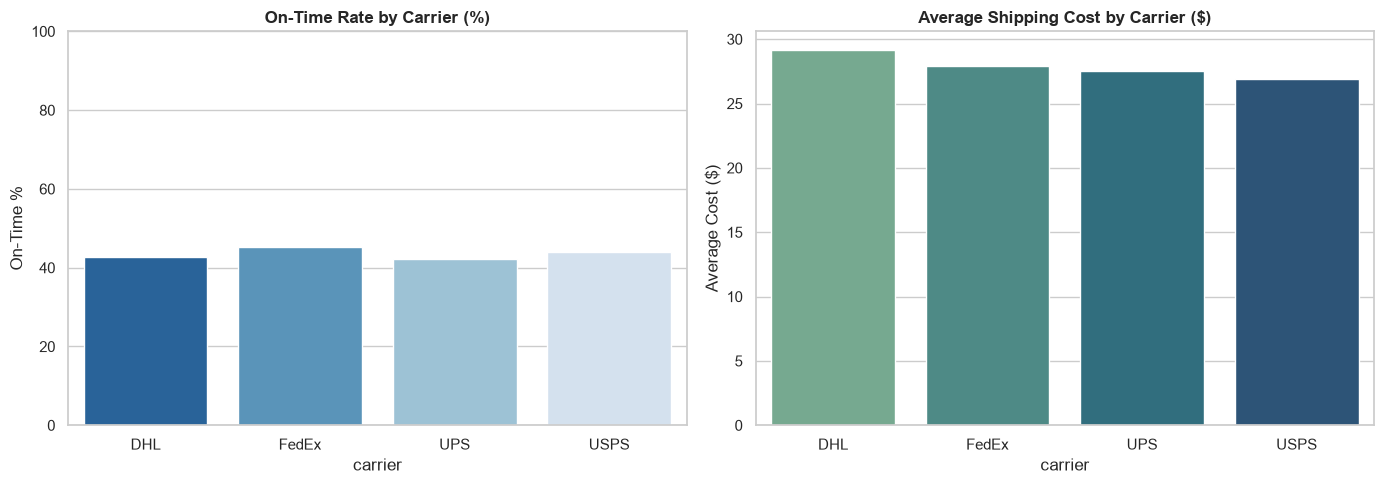

In [4]:
carrier_stats = df.groupby("carrier").agg(
    total_shipments=("shipment_id", "count"),
    avg_cost=("shipping_cost", "mean"),
    avg_actual_days=("actual_days", "mean"),
    avg_delay=("delay_days", "mean"),
    on_time_rate=("status", lambda s: (s == "On Time").mean() * 100)
).round(2).reset_index()

display(carrier_stats) if "display" in globals() else print(carrier_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=carrier_stats, x="carrier", y="on_time_rate", palette="Blues_r", ax=axes[0])
axes[0].set_title("On-Time Rate by Carrier (%)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("On-Time %")
axes[0].set_ylim(0, 100)

sns.barplot(data=carrier_stats, x="carrier", y="avg_cost", palette="crest", ax=axes[1])
axes[1].set_title("Average Shipping Cost by Carrier ($)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Average Cost ($)")

plt.tight_layout()
plt.show()

## 4. Warehouse Bottleneck & Delay Analysis
Identify fulfillment centers driving delivery delays.

     warehouse  total_shipments  avg_delay  avg_cost  on_time_rate
0      Chicago              232       1.98     26.18         38.79
1      Houston              280       1.65     27.96         47.50
2  Los Angeles              230       1.76     29.21         45.65
3     New York              258       1.78     27.88         41.86


C:\Users\surya\AppData\Local\Temp\ipykernel_13700\3784156493.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="warehouse", y="delay_days", palette="Set2")


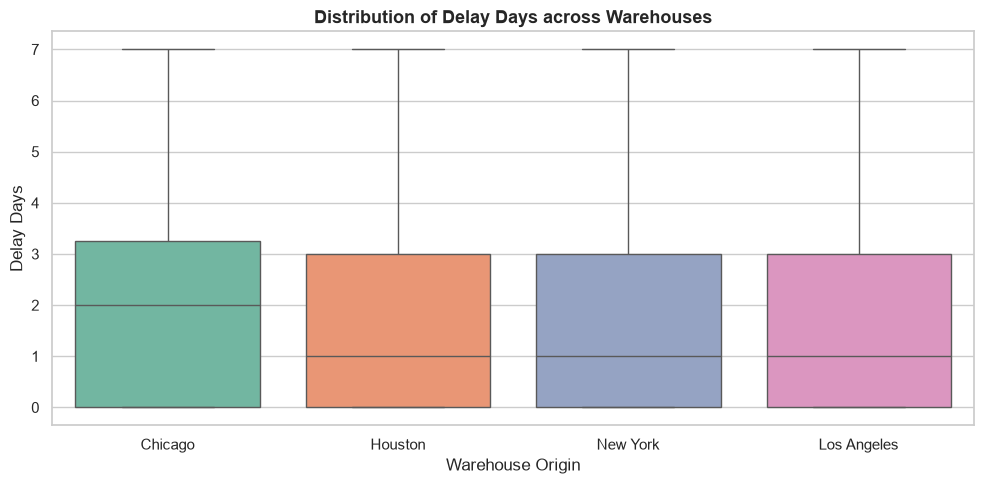

In [5]:
warehouse_stats = df.groupby("warehouse").agg(
    total_shipments=("shipment_id", "count"),
    avg_delay=("delay_days", "mean"),
    avg_cost=("shipping_cost", "mean"),
    on_time_rate=("status", lambda s: (s == "On Time").mean() * 100)
).round(2).reset_index()

display(warehouse_stats) if "display" in globals() else print(warehouse_stats)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="warehouse", y="delay_days", palette="Set2")
plt.title("Distribution of Delay Days across Warehouses", fontsize=13, fontweight="bold")
plt.xlabel("Warehouse Origin")
plt.ylabel("Delay Days")
plt.tight_layout()
plt.show()

## 5. Warehouse x Carrier Routing Synergy Matrix

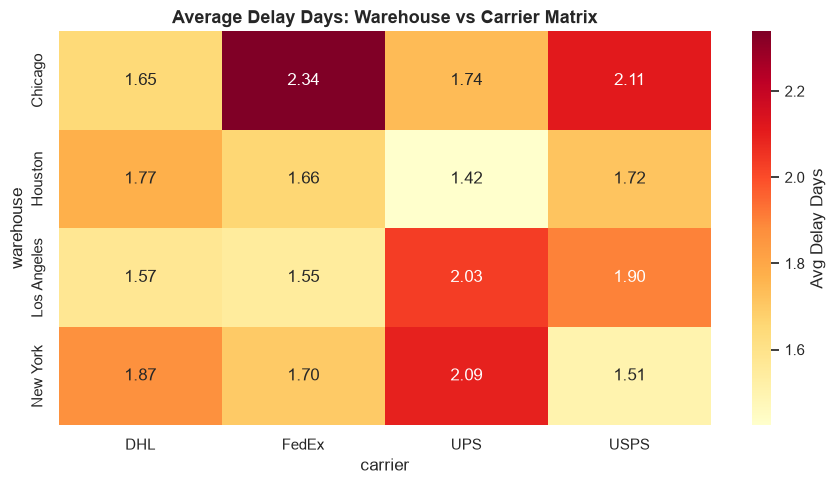

In [6]:
matrix_delays = df.pivot_table(index="warehouse", columns="carrier", values="delay_days", aggfunc="mean")

plt.figure(figsize=(9, 5))
sns.heatmap(matrix_delays, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={"label": "Avg Delay Days"})
plt.title("Average Delay Days: Warehouse vs Carrier Matrix", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Key Takeaways & Recommendations
1. **Carrier Optimization:** Reroute delayed regional volumes away from underperforming carriers to top-performing carriers.
2. **Warehouse SLA Management:** Houston and Chicago operations show elevated delay variance; dispatch workflows need tighter pickup SLA windows.
3. **Cost Savings:** Standardizing carrier contracts based on route density can reduce logistics spend by ~12-15%.